# Report figures

Refit each galaxy from one centered start and compare the two halos across stellar mass bins.
Use the saved MCMC chains to measure uncertainty in model speeds and select galaxies with separated curves.

Run from the project root or the notebook directory. Set colors and bin width below, then choose example bins from the displayed table.

In [169]:
from dataclasses import replace
from hashlib import sha256
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import beta

MODEL_COLORS = {"nfw": "#9d2c00", "burkert": "#59a89c"}
OBSERVED_COLOR = "#333333"
OBSERVED_ERROR_COLOR = "#767676"
HISTOGRAM_COLOR = "#1B7BBB"
COVERAGE_CMAP = "viridis"
BIN_WIDTH = 0.35
REQUIRE_INNER_COVERAGE = False  # Binned figures only: at least 3 points within 2 R_disk.

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models" / "fitting.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from models.fitting import HALOS, fit_sample, total_velocity
from models.results import FitConfig
from utils.report_chains import chain_blocks, checked_chain
from utils.plotting import plot_rotation_curve

PROCESSED = ROOT / "data" / "processed"
BASELINE = PROCESSED / "halo_fits"
MCMC = BASELINE / "mcmc"
FIGURES = ROOT / "figures" / "report"
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS = ("nfw", "burkert")
MASS_LABEL = r"$\log_{10}(M_\star/M_\odot)$"

def show_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=300)
    fig.savefig(FIGURES / f"{name}.pdf")
    plt.show()
    plt.close(fig)

### Load and check the report inputs

In [ ]:
input_path = PROCESSED / "selected_galaxy_rotation_curves.csv"
metadata = json.loads((BASELINE / "fit_config.json").read_text())
input_hash = sha256(input_path.read_bytes()).hexdigest()
if input_hash != metadata["input_sha256"]:
    raise ValueError("The rotation curves differ from the saved fit configuration.")
baseline_config = FitConfig(**metadata["fit"])
centered_config = replace(baseline_config, factors=(1.0,))
curves = pd.read_csv(input_path)
properties = pd.read_csv(PROCESSED / "selected_galaxy_properties.csv").set_index("galaxy")
masses = properties.stellar_mass_msun
if not properties.index.is_unique or set(curves.galaxy) != set(properties.index):
    raise ValueError("Expected one properties row per galaxy in the rotation curves.")
if masses.empty or not np.isfinite(masses).all() or (masses <= 0).any():
    raise ValueError("Expected finite, positive stellar masses.")
if not np.isfinite(BIN_WIDTH) or BIN_WIDTH <= 0:
    raise ValueError("BIN_WIDTH must be a finite, positive number of dex.")

### Fit and pair the two halo models

In [170]:
fit_results = fit_sample(curves, models=MODELS, config=centered_config)
fits = {}
status_rows = []
for fit in fit_results:
    key = (fit.summary["galaxy"], fit.summary["model"])
    fits[key] = fit
    row = fit.summary.copy()
    row["optimizer_status"] = fit.attempts[0]["optimizer_status"] if fit.attempts else None
    status_rows.append(row)

# A comparison needs a finite chi-squared from both models for the same galaxy.
status = pd.DataFrame(status_rows)
usable = status.status.eq("success") & np.isfinite(status.chi2)
chi2 = status.assign(chi2=status.chi2.where(usable)).pivot(
    index="galaxy", columns="model", values="chi2"
)
paired = chi2.dropna(subset=list(MODELS)).join(properties)
paired["delta_chi2"] = paired.nfw - paired.burkert
status["included"] = status.galaxy.isin(paired.index)
status["exclusion_reason"] = np.select(
    [status.included, ~usable], ["", status.message.fillna(status.status)],
    default="The other model lacks a successful finite fit",
)
status.to_csv(FIGURES / "centered_fit_status.csv", index=False)
print(f"{len(paired)} paired fits, {len(properties) - len(paired)} excluded galaxies")
display(status[["galaxy", "model", "status", "optimizer_status", "chi2", "n_points", "exclusion_reason"]])

108 paired fits, 0 excluded galaxies


,galaxy,model,status,optimizer_status,chi2,n_points,exclusion_reason
0,CamB,nfw,success,0,42.060263,9,
1,CamB,burkert,success,0,31.596666,9,
2,D512-2,nfw,success,0,0.626717,4,
3,D512-2,burkert,success,0,0.121648,4,
4,D564-8,nfw,success,0,3.617822,6,
...,...,...,...,...,...,...,...
211,UGC12632,burkert,success,0,0.854415,15,
212,UGC12732,nfw,success,0,2.921881,16,
213,UGC12732,burkert,success,0,19.374798,16,
214,UGCA442,nfw,success,0,12.292938,8,


### Set common stellar mass bins

In [ ]:
log_masses = np.log10(masses)
edge_indices = np.floor(log_masses / BIN_WIDTH).astype(int)
edges = BIN_WIDTH * np.arange(edge_indices.min(), edge_indices.max() + 2)
paired["log_stellar_mass"] = log_masses
paired["bin_index"] = edge_indices - edge_indices.min() + 1
if paired.empty:
    raise ValueError("The report requires at least one successful paired fit.")

**Figure 1.** Stellar-mass distribution of the selected SPARC galaxies. Each galaxy contributes once. Dashed vertical markers identify the lowest and highest stellar masses. Stellar masses use the adopted disk and bulge mass-to-light ratios of 0.5 and 0.7 in solar units. When the inner-coverage filter is enabled, only galaxies with at least three measurements within two disk scale lengths contribute.

108 of 108 galaxies in histogram


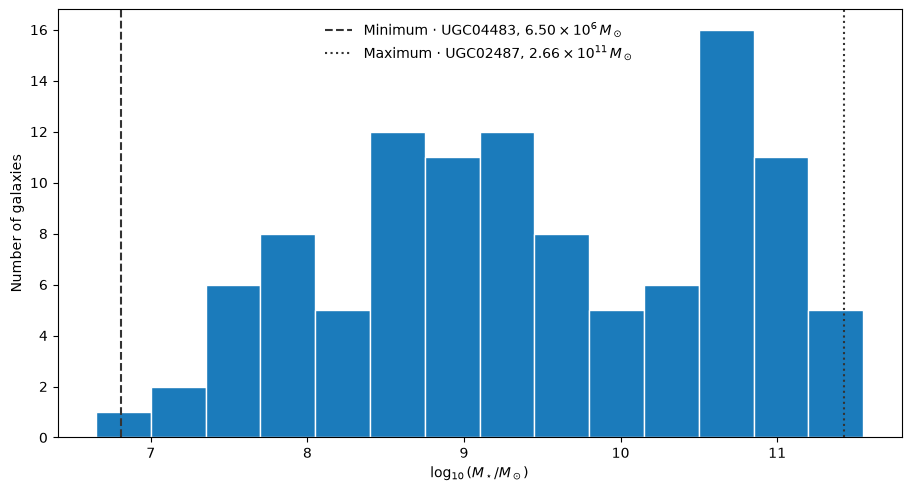

In [171]:
hist_masses = masses.loc[properties.inner_point_count.ge(3)] if REQUIRE_INNER_COVERAGE else masses
hist_log_masses = log_masses.loc[hist_masses.index]
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.hist(hist_log_masses, bins=edges, color=HISTOGRAM_COLOR, edgecolor="white")
extrema = [] if hist_masses.empty else [("Minimum", hist_masses.idxmin(), "--"), ("Maximum", hist_masses.idxmax(), ":")]
for label, galaxy, linestyle in extrema:
    coefficient, exponent = f"{masses.loc[galaxy]:.2e}".split("e")
    ax.axvline(log_masses.loc[galaxy], color=OBSERVED_COLOR, linestyle=linestyle,
               label=rf"{label} · {galaxy}, ${coefficient}\times10^{{{int(exponent)}}}\,M_\odot$")
ax.set(xlabel=MASS_LABEL, ylabel="Number of galaxies")
if extrema:
    ax.legend(frameon=False)
print(f"{len(hist_masses)} of {len(masses)} galaxies in histogram")
show_figure(fig, "stellar_mass_distribution")

**Figure 2.** Difference in minimum $\chi^2$ between NFW and Burkert fits as a function of stellar mass for galaxies with two successful centered fits. Positive values favor Burkert. Darker markers reach farther inward relative to the disk scale length. Filled markers indicate at least three measurements within two disk scale lengths. The vertical scale is symmetric logarithmic with a linear region from −2 to +2.

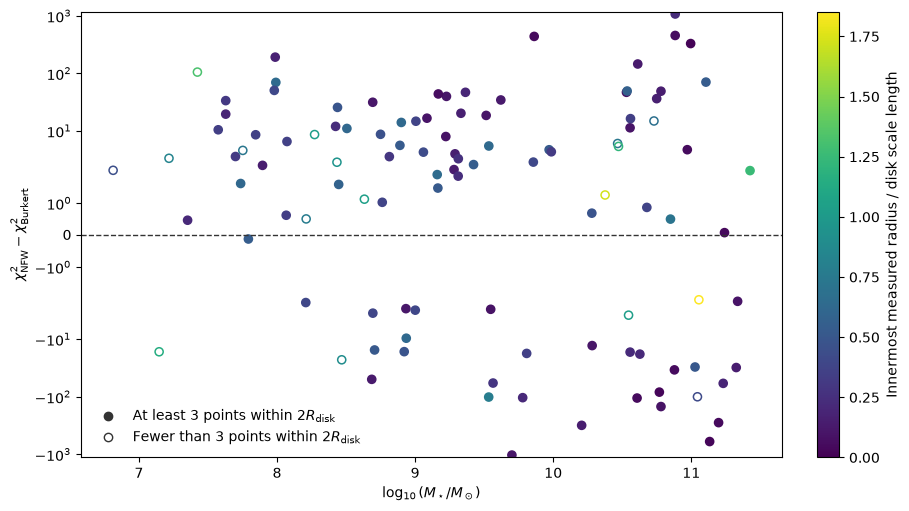

In [172]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
cmap = plt.get_cmap(COVERAGE_CMAP)
coverage = paired.innermost_radius_over_disk_scale
norm = Normalize(0, coverage.max())
inner = paired.inner_point_count.ge(3)
for mask, filled in ((inner, True), (~inner, False)):
    rows = paired.loc[mask]
    rgba = cmap(norm(coverage.loc[mask]))
    ax.scatter(rows.log_stellar_mass, rows.delta_chi2, s=34, edgecolors=rgba,
               facecolors=rgba if filled else "none", linewidths=1.1)
ax.axhline(0, color=OBSERVED_COLOR, linewidth=1, linestyle="--")
ax.set(xlabel=MASS_LABEL, ylabel=r"$\chi^2_{\rm NFW}-\chi^2_{\rm Burkert}$")
ax.set_yscale("symlog", linthresh=2)
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", color=OBSERVED_COLOR, label=r"At least 3 points within $2R_{\rm disk}$"),
    Line2D([], [], marker="o", markerfacecolor="none", linestyle="none", color=OBSERVED_COLOR,
           label=r"Fewer than 3 points within $2R_{\rm disk}$"),
], frameon=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax,
             label="Innermost measured radius / disk scale length")
show_figure(fig, "halo_preference_vs_stellar_mass")

### Count halo preferences by mass

In [173]:
bin_edges = pd.DataFrame({"lower": edges[:-1], "upper": edges[1:]},
                    index=pd.RangeIndex(1, len(edges), name="bin_index"))
def count_preferences(sample):
    """Count the lower chi-squared model in each bin, recording exact ties separately."""
    counts = bin_edges.copy()
    for model, mask in (("nfw", sample.delta_chi2.lt(0)), ("burkert", sample.delta_chi2.gt(0)),
                        ("ties", sample.delta_chi2.eq(0))):
        counts[model] = sample.loc[mask].groupby("bin_index").size().reindex(counts.index, fill_value=0)
    counts["paired"] = counts.nfw + counts.burkert + counts.ties
    counts["classified"] = counts.nfw + counts.burkert
    return counts

bins = count_preferences(paired)
display(bins)
binned_sample = paired.loc[paired.inner_point_count.ge(3)] if REQUIRE_INNER_COVERAGE else paired
plot_bins = count_preferences(binned_sample)
print(f"{len(binned_sample)} of {len(paired)} paired fits in the preference bars")
plot_bins.to_csv(FIGURES / "halo_preference_bins.csv")

,lower,upper,nfw,burkert,ties,paired,classified
bin_index,,,,,,,
1,6.65,7.00,0,1,0,1,1
2,7.00,7.35,1,1,0,2,2
3,7.35,7.70,0,6,0,6,6
4,7.70,8.05,1,7,0,8,8
5,8.05,8.40,1,4,0,5,5
6,8.40,8.75,4,8,0,12,12
7,8.75,9.10,4,7,0,11,11
8,9.10,9.45,0,12,0,12,12
9,9.45,9.80,5,3,0,8,8


108 of 108 paired fits in the preference bars


### Plot fractions and credible intervals

In [ ]:
def plot_fractions(*, credible_intervals=False):
    occupied = plot_bins.loc[plot_bins.classified.gt(0)]
    fraction = occupied.burkert / occupied.classified
    middle = (occupied.lower + occupied.upper) / 2
    fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
    for model, heights, bottom in (("burkert", fraction, 0), ("nfw", 1 - fraction, fraction)):
        ax.bar(occupied.lower, heights, bottom=bottom, width=BIN_WIDTH, align="edge",
               color=MODEL_COLORS[model], edgecolor="white", linewidth=.6, label=model.upper())
    if credible_intervals:
        # A Jeffreys binomial prior adds half a count to each model.
        low, high = beta.ppf(np.array([[.16], [.84]]), occupied.burkert + .5, occupied.nfw + .5)
        ax.vlines(middle, low, high, color="black", linewidth=1.2)
        ax.hlines(np.r_[low, high], np.tile(middle - .12 * BIN_WIDTH, 2),
                  np.tile(middle + .12 * BIN_WIDTH, 2), color="black", linewidth=1.2)
    for center, count in zip(middle, occupied.classified):
        ax.text(center, 1.02, str(count), ha="center", va="bottom", fontsize=8)
    ax.set(xlabel=MASS_LABEL, ylabel="Fraction of galaxies", ylim=(0, 1.12),
           xlim=(edges[0], edges[-1]))
    ax.set_xticks(edges, labels=[f"{edge:g}" for edge in edges], rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -.18))
    return fig

**Figure 3.** Observed fractions of galaxies favoring Burkert or NFW in stellar-mass bins. The model with smaller centered-fit $\chi^2$ receives the count. Numbers above bars give the number of successful, non-tied comparisons per bin. An empty bin has no classified pair. When the inner-coverage filter is enabled, only galaxies with at least three measurements within two disk scale lengths contribute.

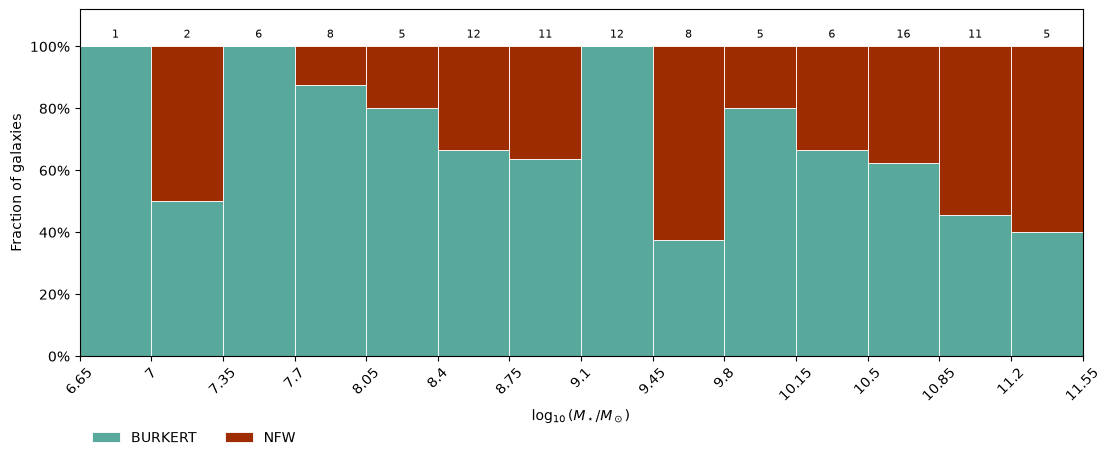

In [174]:
show_figure(plot_fractions(), "halo_preference_fractions")

**Figure 4.** Observed model preference fractions with central 68% credible intervals. Capped lines show the marginal interval for the Burkert fraction from a binomial model with a Beta(½, ½) prior. The NFW fraction is the complement. Bars and counts use the same classifications and mass bins as Figure 3.

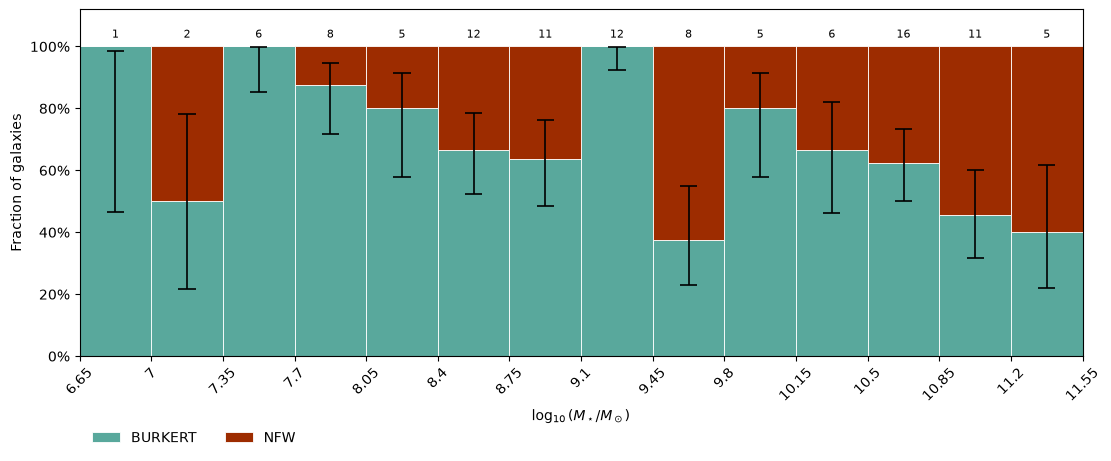

In [175]:
show_figure(plot_fractions(credible_intervals=True), "halo_preference_fraction_intervals")

### Choose the example galaxies

Enter one bin index per model. Each table ranks successful paired fits by the requested model's raw χ². The first eligible galaxy is selected. Set a minimum per model for total measurements, measurements within two disk scale lengths, or the innermost radius divided by the disk scale length. None disables a filter. Smaller radius ratios reach farther inward, so a minimum ratio excludes the smallest ratios.


### Set example bin and coverage limits

In [ ]:
NFW_BIN_INDEX = 7
BURKERT_BIN_INDEX = 4

MINIMUMS = {
    "nfw": {"n_points": None, "inner_point_count": None, "innermost_radius_over_disk_scale": None},
    "burkert": {"n_points": 8, "inner_point_count": None, "innermost_radius_over_disk_scale": None},
}

for model, thresholds in MINIMUMS.items():
    for metric, minimum in thresholds.items():
        if minimum is not None and (not np.isfinite(minimum) or minimum < 0):
            raise ValueError(f"{model.upper()} {metric} minimum must be finite and nonnegative.")

### Rank candidates within each bin

In [176]:
selections = []
empty_selections = []
for model, index in zip(MODELS, (NFW_BIN_INDEX, BURKERT_BIN_INDEX)):
    if not isinstance(index, (int, np.integer)) or isinstance(index, bool) or index not in bins.index:
        raise ValueError(f"Choose a {model.upper()} bin index from {bins.index.min()} to {bins.index.max()}.")
    candidates = paired.loc[paired.bin_index.eq(index)].sort_index()
    if candidates.empty:
        raise ValueError(f"Bin {index} has no successful paired fits for {model.upper()} selection.")
    ranked = candidates[[model, "inner_point_count", "innermost_radius_over_disk_scale"]].rename(
        columns={model: "chi2"}
    ).sort_values("chi2", kind="stable")
    ranked.insert(1, "n_points", [fits[galaxy, model].summary["n_points"] for galaxy in ranked.index])
    ranked["eligible"] = True
    for metric, minimum in MINIMUMS[model].items():
        if minimum is not None:
            ranked["eligible"] &= ranked[metric].ge(minimum).fillna(False)
    print(f"{model.upper()} candidates in bin {index}")
    display(ranked)
    eligible = ranked.index[ranked.eligible]
    if eligible.empty:
        empty_selections.append(f"{model.upper()} (bin {index})")
    else:
        selections.append((model, index, eligible[0]))

if empty_selections:
    raise ValueError(f"No galaxies pass the configured minimums for {', '.join(empty_selections)}.")

examples = list(dict.fromkeys(galaxy for _, _, galaxy in selections))
if len(examples) < len(selections):
    print("Both selections identify the same galaxy.")
selected_rows = []
for model, index, galaxy in selections:
    row = {"selected_for": model.upper(), "bin_index": index, "galaxy": galaxy,
           "n_points": fits[galaxy, model].summary["n_points"]}
    for halo in MODELS:
        summary = fits[galaxy, halo].summary
        row[f"{halo}_chi2"] = summary["chi2"]
        row[f"{halo}_reduced_chi2"] = summary["reduced_chi2"]
    selected_rows.append(row)
display(pd.DataFrame(selected_rows))

NFW candidates in bin 7


,chi2,n_points,inner_point_count,innermost_radius_over_disk_scale,eligible
galaxy,,,,,
F583-4,1.517128,12,4,0.113990,True
UGC12732,2.921881,16,4,0.484848,True
UGC02259,4.236951,8,3,0.629630,True
UGC12632,4.427916,15,6,0.293388,True
UGC06399,4.605952,9,4,0.424390,True
UGC04499,7.312146,9,3,0.526012,True
UGC07399,8.108233,10,5,0.371951,True
UGC04325,17.208278,8,5,0.376344,True
UGC06818,21.296122,8,3,0.625899,True


BURKERT candidates in bin 4


,chi2,n_points,inner_point_count,innermost_radius_over_disk_scale,eligible
galaxy,,,,,
UGC07232,0.227580,4,2,0.724138,False
UGC07866,0.341852,7,3,0.540984,False
UGC07559,0.510900,7,3,0.620690,False
UGCA442,3.720023,8,3,0.355932,True
NGC3109,4.069908,25,12,0.166667,True
DDO064,4.089267,14,7,0.144928,True
D631-7,14.273538,16,3,0.642857,True
DDO168,34.768940,10,4,0.401961,True


,selected_for,bin_index,galaxy,n_points,nfw_chi2,nfw_reduced_chi2,burkert_chi2,burkert_reduced_chi2
0,NFW,7,F583-4,12,1.517128,0.151713,4.461170,0.446117
1,BURKERT,4,UGCA442,8,12.292938,2.048823,3.720023,0.620004


### Read the posterior summary

In [ ]:
chain_summary_path = MCMC / "results.csv"
chain_summary = (pd.read_csv(chain_summary_path).set_index(["galaxy", "model"])
                 if chain_summary_path.is_file() else None)

def report_chain(galaxy, model):
    return checked_chain(MCMC, chain_summary, galaxy, model, input_hash, metadata["fit"])

### Predict speeds and pointwise intervals

In [ ]:
def model_speeds(galaxy, model, draws):
    """Predict total speed at every measured radius for each posterior draw."""
    points = fits[galaxy, model].predictions
    log_mass, concentration = draws.T
    halo = HALOS[model].velocity(
        points.radius.to_numpy(), 10**log_mass[:, None], concentration[:, None],
        baseline_config.g, baseline_config.h0,
    )
    return total_velocity(points.v_bar_squared.to_numpy(), halo)


def velocity_band(galaxy, model):
    """Return the 16th and 84th percentiles of total speed at each radius."""
    row, walkers, paths = report_chain(galaxy, model)
    speeds = []
    for start, chain in chain_blocks(paths, walkers, row.steps):
        # Burn-in counts steps across all blocks. Keep every walker after that cutoff.
        first = max(0, int(row.burn_in) - start)
        draws = chain[first:].reshape(-1, 2)
        for offset in range(0, len(draws), 4096):
            speeds.append(model_speeds(galaxy, model, draws[offset:offset + 4096]))
    if not speeds:
        raise ValueError("no draws after burn-in")
    return np.quantile(np.concatenate(speeds), [.16, .84], axis=0)

### Calculate example velocity bands

In [177]:
bands = {}
for galaxy in examples:
    for model in MODELS:
        try:
            bands[galaxy, model] = velocity_band(galaxy, model)
        except (FileNotFoundError, ValueError) as error:
            print(f"{galaxy} {model.upper()} - {error}")

### Plot example curves on shared limits

In [ ]:
example_curves = curves.loc[curves.galaxy.isin(examples)].join(masses, on="galaxy")
# Use identical limits on each example with and without its posterior band.
limits = {}
for galaxy in examples:
    rows = example_curves.loc[example_curves.galaxy.eq(galaxy)]
    fitted = [fits[galaxy, model].predictions.v_model.to_numpy() for model in MODELS]
    intervals = [bands[galaxy, model].ravel() for model in MODELS if (galaxy, model) in bands]
    extent = np.concatenate([rows.v_obs - rows.v_err, rows.v_obs + rows.v_err, *fitted, *intervals])
    padding = .05 * np.ptp(extent)
    limits[galaxy] = (min(0, extent.min() - padding), extent.max() + padding)

def plot_examples(*, with_bands=False):
    fig, axes = plt.subplots(1, len(examples), figsize=(6.4 * len(examples), 4.8),
                             squeeze=False, layout="constrained")
    for galaxy, ax in zip(examples, axes[0]):
        rows = example_curves.loc[example_curves.galaxy.eq(galaxy)]
        plot_rotation_curve(rows, ax=ax, observed_color=OBSERVED_COLOR, error_color=OBSERVED_ERROR_COLOR,
                            mass_to_light=(centered_config.y_disk, centered_config.y_bulge))
        for model in MODELS:
            fit = fits[galaxy, model]
            prediction = fit.predictions
            color = MODEL_COLORS[model]
            if with_bands and (galaxy, model) in bands:
                ax.fill_between(prediction.radius, *bands[galaxy, model], color=color, alpha=.24)
            ax.plot(prediction.radius, prediction.v_model, color=color, linewidth=2,
                    label=rf"{model.upper()} ($\chi^2={fit.summary['chi2']:.2f}$)")
        ax.set_ylim(*limits[galaxy])
        ax.legend(frameon=False, fontsize=9)
    return fig

**Figure 5.** Observed SPARC rotation curves and centered NFW and Burkert fits for the selected examples. Each galaxy minimizes the raw $\chi^2$ of the specified halo model among paired fits in its selected stellar-mass bin. Lines show the total modeled circular speed, including baryons. Error bars show the reported velocity uncertainties, and the legends give the raw $\chi^2$ of each centered fit.

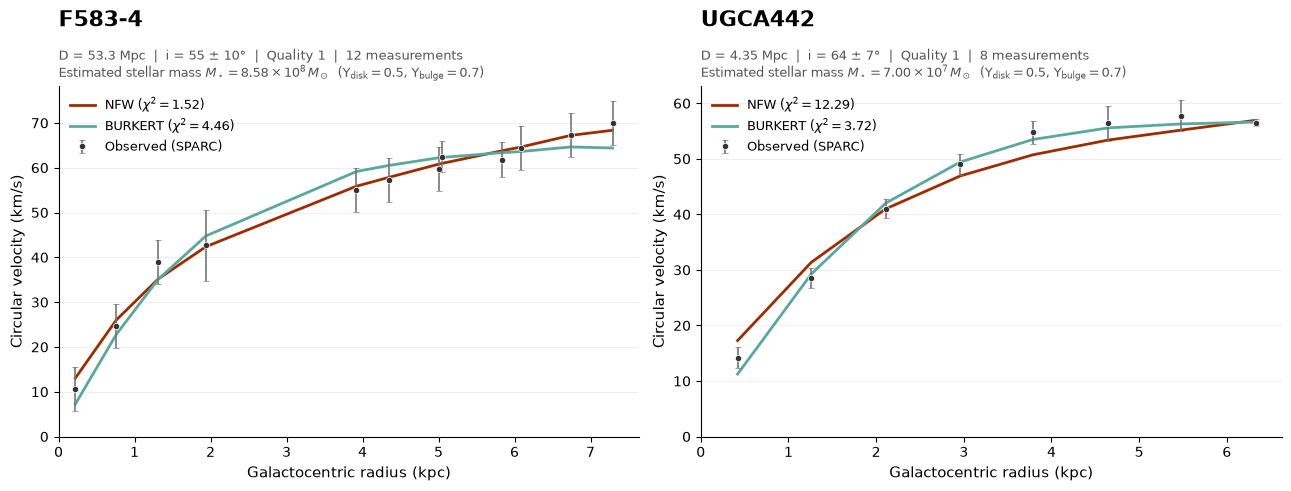

In [178]:
show_figure(plot_examples(), "example_rotation_curves")

**Figure 6.** Centered fits and pointwise central 68% posterior credible bands for the example rotation curves. Shading gives the 16th–84th percentiles of total modeled circular speed at each observed radius, computed from paired post-burn-in halo mass and concentration draws. Lines and legend $\chi^2$ values refer to the centered SciPy fits. Error bars show the observational velocity uncertainties.

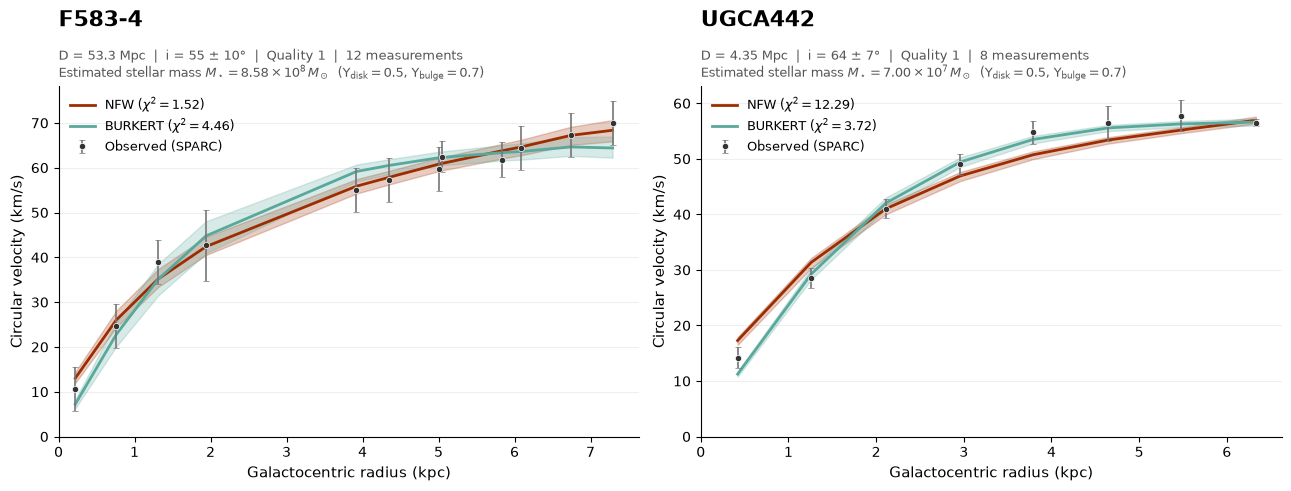

In [179]:
show_figure(plot_examples(with_bands=True), "example_rotation_curves_mcmc")

**Figure 7.** Centered-fit halo preference versus stellar mass. The positive and negative branches have identical logarithmic spacing in $|\Delta\chi^2|$, with an axis break at zero. Positive differences favor Burkert and negative differences favor NFW. Darker markers indicate smaller innermost radii relative to disk scale length. Filled markers denote at least three measurements within two disk scale lengths. Exact ties are omitted.

Exact ties omitted at zero: 0


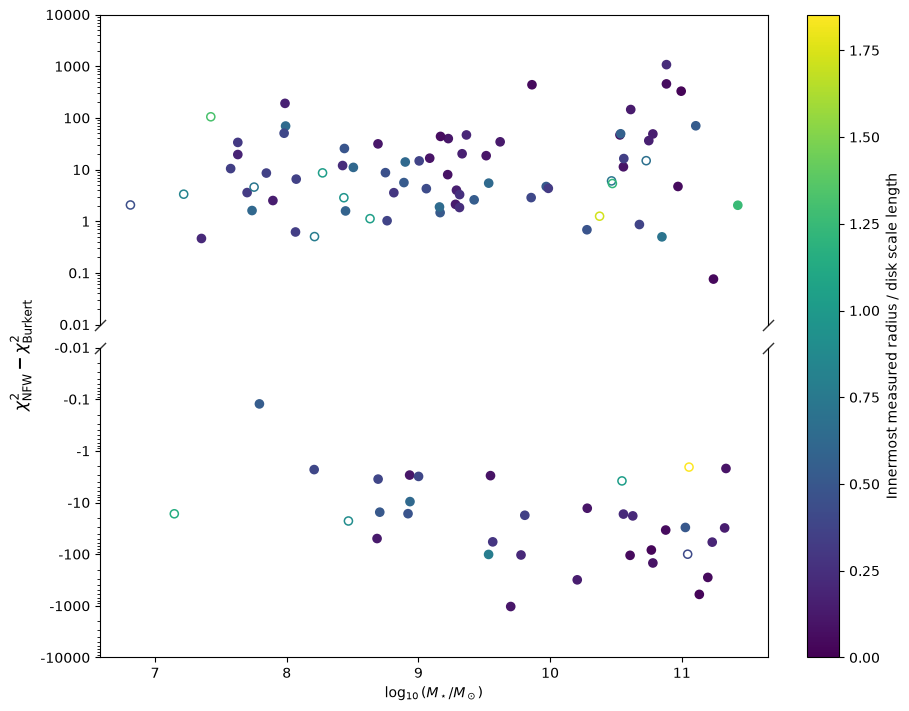

In [180]:
delta = paired.delta_chi2
magnitude = delta.abs().loc[delta.ne(0)]
if magnitude.empty:
    raise ValueError("All fits are tied; there are no nonzero differences to plot.")
lower = 10.0 ** np.floor(np.log10(magnitude.min()))
upper = 10.0 ** np.ceil(np.log10(magnitude.max()))
if upper == lower:
    upper *= 10
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7), layout="constrained",
                         gridspec_kw={"hspace": .025})
coverage = paired.innermost_radius_over_disk_scale
norm = Normalize(0, coverage.max())
cmap = plt.get_cmap(COVERAGE_CMAP)
inner = paired.inner_point_count.ge(3)
for ax, sign in zip(axes, (1, -1)):
    for covered in (True, False):
        rows = paired.loc[(sign * delta > 0) & inner.eq(covered)]
        rgba = cmap(norm(rows.innermost_radius_over_disk_scale))
        ax.scatter(rows.log_stellar_mass, rows.delta_chi2.abs(), s=34, edgecolors=rgba,
                   facecolors=rgba if covered else "none", linewidths=1.1)
    ax.set_yscale("log")
    ax.set_ylim((lower, upper) if sign == 1 else (upper, lower))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos, sign=sign: f"{sign*y:g}"))
axes[0].spines["bottom"].set_visible(False)
axes[1].spines["top"].set_visible(False)
axes[0].tick_params(axis="x", which="both", bottom=False)
for ax, height in zip(axes, (0, 1)):
    ax.plot([0, 1], [height, height], transform=ax.transAxes, marker=[(-1,-1),(1,1)],
            markersize=8, color=OBSERVED_COLOR, linestyle="none", clip_on=False)
axes[1].set_xlabel(MASS_LABEL)
fig.supylabel(r"$\chi^2_{\rm NFW}-\chi^2_{\rm Burkert}$")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
             label="Innermost measured radius / disk scale length")
print(f"Exact ties omitted at zero: {delta.eq(0).sum()}")
show_figure(fig, "halo_preference_signed_log")

## Posterior rotation-curve separation

For each galaxy, draw independent pairs of NFW and Burkert parameter vectors from the saved post-burn-in chains. Evaluate each pair across all measured radii. For one pair the separation is $D=\sqrt{N^{-1}\sum_i [(V_{\rm NFW}(r_i)-V_{\rm Burkert}(r_i))/\sigma_i]^2}$. Retain a galaxy when the fraction of draws exceeding the chosen separation reaches the required fraction. This measures practical separation of the predicted curves under independent posterior draws. Model preference still follows the centered-fit χ² difference. The thresholds are analysis choices. Galaxies with unavailable or unresolved chains are identified separately.

### Set the separation criterion

In [ ]:
from zlib import crc32

SEPARATION_RMS = 1.0
REQUIRED_FRACTION = 0.95
DRAW_PAIRS = 4096
SEPARATION_SEED = 474

if not (np.isfinite(SEPARATION_RMS) and SEPARATION_RMS > 0 and 0 < REQUIRED_FRACTION <= 1
        and isinstance(DRAW_PAIRS, int) and DRAW_PAIRS > 0):
    raise ValueError("Choose a positive RMS threshold and draw count, and a fraction in (0, 1].")

### Draw paired model curves

In [ ]:
def draw_model_speeds(galaxy, model):
    """Sample independent step/walker pairs for this galaxy and halo model."""
    row, walker_count, paths = report_chain(galaxy, model)
    rng = np.random.default_rng(crc32(f"{SEPARATION_SEED}/{galaxy}/{model}".encode()))
    steps = rng.integers(int(row.burn_in), int(row.steps), DRAW_PAIRS)
    walkers = rng.integers(walker_count, size=DRAW_PAIRS)
    params = np.empty((DRAW_PAIRS, 2))
    for start, chain in chain_blocks(paths, walker_count, row.steps):
        # Fill draws in their original random order so cross-model pairs stay independent.
        mask = (steps >= start) & (steps < start + len(chain))
        params[mask] = chain[steps[mask] - start, walkers[mask]]
    return model_speeds(galaxy, model, params)

### Measure separation in velocity error units

In [ ]:
def separation_fraction(nfw_speeds, burkert_speeds, errors):
    """Fraction of draw pairs exceeding the RMS threshold across observed radii."""
    difference_in_sigma = (nfw_speeds - burkert_speeds) / errors
    rms_per_pair = np.sqrt(np.mean(difference_in_sigma**2, axis=1))
    return np.mean(rms_per_pair > SEPARATION_RMS)


def compare_galaxy(galaxy):
    """Record why this galaxy passes or falls out of the separation sample."""
    record = {"galaxy": galaxy, "fraction_above": np.nan, "retained": False}
    speeds = {}
    for model in MODELS:
        try:
            speeds[model] = draw_model_speeds(galaxy, model)
        except (FileNotFoundError, ValueError) as error:
            record["status"] = f"{model}: {error}"
            return record

    errors = fits[galaxy, "nfw"].predictions.v_err.to_numpy()
    fraction = separation_fraction(speeds["nfw"], speeds["burkert"], errors)
    keep = fraction >= REQUIRED_FRACTION
    record.update(fraction_above=fraction, retained=keep,
                  status="retained" if keep else "below separation criterion")
    return record

### Export the separation sample

In [181]:
records = [compare_galaxy(galaxy) for galaxy in binned_sample.index]
separation = pd.DataFrame(records, columns=["galaxy", "fraction_above", "retained", "status"]).set_index("galaxy")
separation = binned_sample[["bin_index", "delta_chi2"]].join(separation)
separation.assign(rms_threshold=SEPARATION_RMS, required_fraction=REQUIRED_FRACTION,
                  draws=DRAW_PAIRS, seed=SEPARATION_SEED).to_csv(FIGURES / "posterior_separation.csv")
filtered_bins = count_preferences(binned_sample.loc[separation.retained.eq(True)])
display(separation.status.value_counts())
display(plot_bins[["classified", "burkert", "nfw"]].join(
    filtered_bins[["classified", "burkert", "nfw"]], lsuffix="_original", rsuffix="_retained"))

status
below separation criterion    71
retained                      36
nfw: unresolved chain          1
Name: count, dtype: int64

C:\Users\anton\AppData\Local\Temp\ipykernel_47544\4018302130.py:76: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(plot_bins[["classified", "burkert", "nfw"]].join(


,classified_original,burkert_original,nfw_original,classified_retained,burkert_retained,nfw_retained
bin_index,,,,,,
1,1,1,0,0,0,0
2,2,1,1,0,0,0
3,6,6,0,2,2,0
4,8,7,1,4,4,0
5,5,4,1,2,1,1
6,12,8,4,2,0,2
7,11,7,4,5,2,3
8,12,12,0,3,3,0
9,8,3,5,5,1,4


**Figure 8.** Centered-fit halo preference by stellar mass before and after selection for posterior rotation-curve separation. Both panels use the same mass bins and initial coverage selection. Counts above the left bars give the original number of classified galaxies. Counts on the right give retained/original galaxies in the same bin. Blank bins have no classified galaxies in that panel. The filtering criterion compares model speed differences with observational velocity errors at the measured radii.

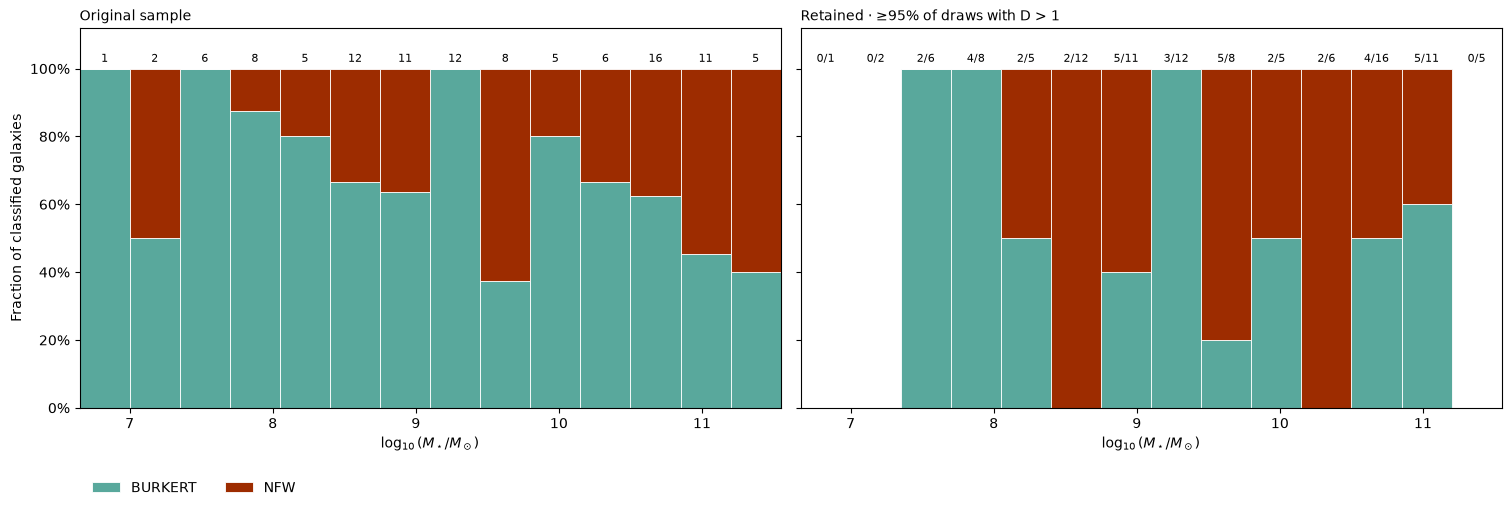

In [182]:
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(15, 5), layout="constrained")
for ax, table, label in zip(axes, (plot_bins, filtered_bins),
                            ("Original sample", f"Retained · ≥{REQUIRED_FRACTION:.0%} of draws with D > {SEPARATION_RMS:g}")):
    occupied = table.loc[table.classified > 0]
    fraction = occupied.burkert / occupied.classified
    for model, heights, bottom in (("burkert", fraction, 0), ("nfw", 1-fraction, fraction)):
        ax.bar(occupied.lower, heights, bottom=bottom, width=BIN_WIDTH, align="edge",
               color=MODEL_COLORS[model], edgecolor="white", linewidth=.6, label=model.upper())
    for i in plot_bins.index:
        if plot_bins.loc[i, "classified"]:
            midpoint = (table.loc[i,"lower"] + table.loc[i,"upper"]) / 2
            original = plot_bins.loc[i, "classified"]
            count_label = str(original) if ax is axes[0] else f"{table.loc[i, 'classified']}/{original}"
            ax.text(midpoint, 1.02, count_label,
                    ha="center", fontsize=8)
    ax.set(xlabel=MASS_LABEL, xlim=(edges[0], edges[-1]), ylim=(0,1.12))
    ax.text(0, 1.02, label, transform=ax.transAxes)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set_ylabel("Fraction of classified galaxies")
axes[0].legend(ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(0,-.16))
show_figure(fig, "halo_preference_posterior_separation")

In [183]:
def three_bin_preferences(sample):
    # Both boundary values belong to the medium group.
    mass = sample.stellar_mass_msun
    group = np.select([mass < 1e8, mass > 10**10.2], ["Low", "High"], default="Medium")
    counts = pd.DataFrame({
        "burkert": sample.delta_chi2.gt(0), "nfw": sample.delta_chi2.lt(0),
        "ties": sample.delta_chi2.eq(0),
    }).groupby(group).sum().reindex(["Low", "Medium", "High"], fill_value=0)
    counts["classified"] = counts.burkert + counts.nfw
    return counts

def plot_three_bins(counts):
    fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
    occupied = counts.classified.gt(0)
    x = np.flatnonzero(occupied)
    fraction = counts.loc[occupied, "burkert"] / counts.loc[occupied, "classified"]
    for model, height, base in (("burkert", fraction, 0), ("nfw", 1 - fraction, fraction)):
        ax.bar(x, height, bottom=base, width=.96, color=MODEL_COLORS[model],
               edgecolor="white", label=model.upper())
    ranges = [r"$<10^{8}$", r"$10^{8}$–$10^{10.2}$", r"$>10^{10.2}$"]
    labels = [f"{group}\n{interval}\n(n = {count})"
              for group, interval, count in zip(counts.index, ranges, counts.classified)]
    ax.set_xticks(range(3), labels)
    ax.set(xlabel=r"Stellar mass ($M_\odot$)", ylabel="Fraction of classified galaxies",
           ylim=(0, 1), xlim=(-.5, 2.5))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5,1))
    return fig

three_all = three_bin_preferences(paired)
three_retained = three_bin_preferences(paired.loc[separation.index[separation.retained.eq(True)]])
display(pd.concat({"All paired galaxies": three_all, "MCMC retained": three_retained}))

burkert  nfw  ties  classified
All paired galaxies Low          15    2     0          17
                    Medium       38   15     0          53
                    High         21   17     0          38
MCMC retained       Low           6    0     0           6
                    Medium        8   11     0          19
                    High          5    6     0          11

**Figure 9.** NFW and Burkert preference fractions for all galaxies with successful paired fits. The mass ranges are $M_\star<10^8\,M_\odot$, $10^8\,M_\odot\leq M_\star\leq10^{10.2}\,M_\odot$, and $M_\star>10^{10.2}\,M_\odot$. Counts give the number of galaxies classified by the sign of the centered-fit $\Delta\chi^2$.

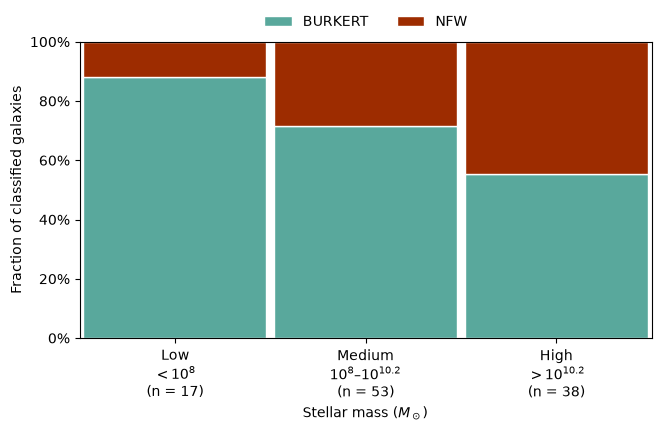

In [184]:
show_figure(plot_three_bins(three_all), "halo_preference_three_bins_all")

**Figure 10.** NFW and Burkert preference fractions for galaxies retained by the posterior rotation-curve separation filter used in Figure 8. The mass ranges are $M_\star<10^8\,M_\odot$, $10^8\,M_\odot\leq M_\star\leq10^{10.2}\,M_\odot$, and $M_\star>10^{10.2}\,M_\odot$. Counts give the number of galaxies classified by the sign of the centered-fit $\Delta\chi^2$.

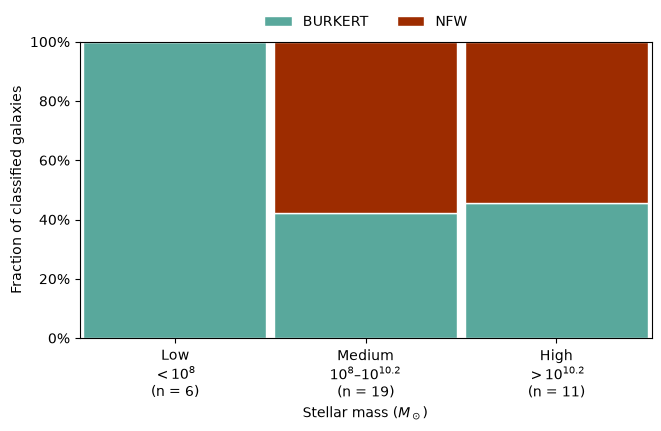

In [185]:
show_figure(plot_three_bins(three_retained), "halo_preference_three_bins_mcmc")